# PriceFusion V0.3 — Text Baseline Models

**Project:** PriceFusion — Multimodal Product Price Intelligence  
**Stage:** V0.3  
**Goal:** Establish reproducible text-only ML baselines using TF-IDF + Ridge and evaluate them with SMAPE.

This notebook will:
- create and persist a group-aware 80/20 train/validation split
- establish a constant median baseline
- train word-level TF-IDF + Ridge models
- compare direct-price vs `log1p(price)` targets
- train character TF-IDF + Ridge
- build a weighted word + character ensemble
- evaluate overall and by price bucket
- save metrics, predictions, vectorizers, models, and split IDs


## 1. Imports

In [1]:
from pathlib import Path
import json
import re
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, median_absolute_error

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_colwidth', 180)

RANDOM_STATE = 42
print('V0.3 environment ready.')

V0.3 environment ready.


## 2. Resolve Project Paths

In [2]:
cwd = Path.cwd().resolve()

if (cwd / 'dataset').exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / 'dataset').exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        'Could not find dataset/. Launch Jupyter from PriceFusion/ or PriceFusion/notebooks/.'
    )

DATASET_DIR = PROJECT_ROOT / 'dataset'
ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'
SPLITS_DIR = ARTIFACTS_DIR / 'splits'
METRICS_DIR = ARTIFACTS_DIR / 'metrics'
PREDICTIONS_DIR = ARTIFACTS_DIR / 'predictions'
MODELS_DIR = PROJECT_ROOT / 'models' / 'v03_text_baselines'
FIGURES_DIR = ARTIFACTS_DIR / 'figures'

for path in [SPLITS_DIR, METRICS_DIR, PREDICTIONS_DIR, MODELS_DIR, FIGURES_DIR]:
    path.mkdir(parents=True, exist_ok=True)

TRAIN_CSV = DATASET_DIR / 'train.csv'

print('Project root :', PROJECT_ROOT)
print('Models dir   :', MODELS_DIR)
print('Splits dir   :', SPLITS_DIR)
print('Metrics dir  :', METRICS_DIR)

Project root : /Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion
Models dir   : /Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/models/v03_text_baselines
Splits dir   : /Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/artifacts/splits
Metrics dir  : /Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/artifacts/metrics


## 3. Load Training Data

In [3]:
df = pd.read_csv(TRAIN_CSV)

required_columns = {'sample_id', 'catalog_content', 'price'}
missing = required_columns - set(df.columns)
assert not missing, f'Missing required columns: {missing}'

assert df['sample_id'].is_unique
assert df['catalog_content'].notna().all()
assert (df['price'] > 0).all()

print('Shape:', df.shape)
display(df.head(3))

Shape: (75000, 4)


,sample_id,catalog_content,image_link,price
0,33127,"Item Name: La Victoria Green Taco Sauce Mild, 12 Ounce (Pack of 6)\nValue: 72.0\nUnit: Fl Oz\n",https://m.media-amazon.com/images/I/51mo8htwTHL.jpg,4.89
1,198967,"Item Name: Salerno Cookies, The Original Butter Cookies, 8 Ounce (Pack of 4)\nBullet Point 1: Original Butter Cookies: Classic butter cookies made with real butter\nBullet Poin...",https://m.media-amazon.com/images/I/71YtriIHAAL.jpg,13.12
2,261251,"Item Name: Bear Creek Hearty Soup Bowl, Creamy Chicken with Rice, 1.9 Ounce (Pack of 6)\nBullet Point 1: Loaded with hearty long grain wild rice and vegetables\nBullet Point 2:...",https://m.media-amazon.com/images/I/51+PFEe-w-L.jpg,1.97


## 4. Normalize Catalog Text for Group-Aware Validation

Exact or near-identical catalog text should remain in the same split. This reduces optimistic validation leakage.

In [4]:
def normalize_group_text(text):
    text = str(text).lower()
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['catalog_group'] = df['catalog_content'].map(normalize_group_text)

print('Rows:', len(df))
print('Unique normalized catalog groups:', df['catalog_group'].nunique())
print('Duplicate rows by normalized text:', df['catalog_group'].duplicated().sum())

Rows: 75000
Unique normalized catalog groups: 74893
Duplicate rows by normalized text: 107


## 5. Create or Reuse the Permanent V0.3 Validation Split

In [5]:
TRAIN_IDS_PATH = SPLITS_DIR / 'train_ids.csv'
VALID_IDS_PATH = SPLITS_DIR / 'validation_ids.csv'

if TRAIN_IDS_PATH.exists() and VALID_IDS_PATH.exists():
    train_ids = pd.read_csv(TRAIN_IDS_PATH)['sample_id']
    valid_ids = pd.read_csv(VALID_IDS_PATH)['sample_id']

    train_mask = df['sample_id'].isin(train_ids)
    valid_mask = df['sample_id'].isin(valid_ids)

    train_idx = np.flatnonzero(train_mask.to_numpy())
    valid_idx = np.flatnonzero(valid_mask.to_numpy())

    print('Reusing existing saved split.')
else:
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=RANDOM_STATE,
    )

    train_idx, valid_idx = next(
        splitter.split(
            df,
            groups=df['catalog_group']
        )
    )

    df.iloc[train_idx][['sample_id']].to_csv(TRAIN_IDS_PATH, index=False)
    df.iloc[valid_idx][['sample_id']].to_csv(VALID_IDS_PATH, index=False)
    print('Created and saved a new permanent split.')

train_df = df.iloc[train_idx].copy().reset_index(drop=True)
valid_df = df.iloc[valid_idx].copy().reset_index(drop=True)

print('Train rows     :', len(train_df))
print('Validation rows:', len(valid_df))

overlap_groups = set(train_df['catalog_group']).intersection(set(valid_df['catalog_group']))
print('Normalized catalog group overlap:', len(overlap_groups))
assert len(overlap_groups) == 0, 'Group leakage detected.'

Created and saved a new permanent split.
Train rows     : 60000
Validation rows: 15000
Normalized catalog group overlap: 0


## 6. Compare Train and Validation Target Distribution

In [6]:
split_summary = pd.DataFrame({
    'split': ['train', 'validation'],
    'rows': [len(train_df), len(valid_df)],
    'price_mean': [train_df['price'].mean(), valid_df['price'].mean()],
    'price_median': [train_df['price'].median(), valid_df['price'].median()],
    'price_std': [train_df['price'].std(), valid_df['price'].std()],
    'price_95pct': [train_df['price'].quantile(0.95), valid_df['price'].quantile(0.95)],
    'price_99pct': [train_df['price'].quantile(0.99), valid_df['price'].quantile(0.99)],
})

display(split_summary)

,split,rows,price_mean,price_median,price_std,price_95pct,price_99pct
0,train,60000,23.703262,14.00,33.889763,76.3020,145.5002
1,validation,15000,23.425221,14.12,31.241628,73.4895,144.1841


## 7. Evaluation Functions

In [7]:
def smape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    denominator = (np.abs(y_true) + np.abs(y_pred)) / 2.0
    numerator = np.abs(y_true - y_pred)

    ratio = np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator, dtype=float),
        where=denominator != 0,
    )
    return float(np.mean(ratio) * 100.0)

def clip_positive(predictions, minimum=0.01):
    return np.maximum(np.asarray(predictions, dtype=float), minimum)

def evaluate_predictions(y_true, y_pred, model_name):
    y_pred = clip_positive(y_pred)
    return {
        'model': model_name,
        'smape': smape(y_true, y_pred),
        'mae': mean_absolute_error(y_true, y_pred),
        'median_ae': median_absolute_error(y_true, y_pred),
        'min_prediction': float(np.min(y_pred)),
        'max_prediction': float(np.max(y_pred)),
    }

def print_metrics(metrics):
    print(f"{metrics['model']}")
    print(f"SMAPE     : {metrics['smape']:.4f}%")
    print(f"MAE       : {metrics['mae']:.4f}")
    print(f"Median AE : {metrics['median_ae']:.4f}")

## 8. Price Buckets for Diagnostics

In [8]:
PRICE_BINS = [0, 5, 10, 25, 50, 100, 250, np.inf]
PRICE_LABELS = ['$0–5', '$5–10', '$10–25', '$25–50', '$50–100', '$100–250', '$250+']

valid_df['price_bucket'] = pd.cut(
    valid_df['price'],
    bins=PRICE_BINS,
    labels=PRICE_LABELS,
    right=False,
    include_lowest=True,
)

display(valid_df['price_bucket'].value_counts(sort=False).to_frame('validation_count'))

,validation_count
price_bucket,
$0–5,2568
$5–10,3077
$10–25,5051
$25–50,2728
$50–100,1222
$100–250,325
$250+,29


## 9. Baseline 0 — Constant Median Price

In [9]:
experiment_results = []
prediction_store = {}

median_price = float(train_df['price'].median())
median_pred = np.full(len(valid_df), median_price, dtype=float)

median_metrics = evaluate_predictions(
    valid_df['price'],
    median_pred,
    'Median Constant Baseline'
)

experiment_results.append(median_metrics)
prediction_store['median_baseline'] = median_pred
print_metrics(median_metrics)

Median Constant Baseline
SMAPE     : 71.9863%
MAE       : 16.2358
Median AE : 8.8325


## 10. Word TF-IDF Vectorization

We begin with a practical vocabulary size suitable for a 75K-row dataset. Later versions can tune this further.

In [10]:
word_vectorizer = TfidfVectorizer(
    analyzer='word',
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.995,
    max_features=180_000,
    sublinear_tf=True,
    strip_accents='unicode',
    dtype=np.float32,
)

X_train_word = word_vectorizer.fit_transform(train_df['catalog_content'])
X_valid_word = word_vectorizer.transform(valid_df['catalog_content'])

print('Word TF-IDF train shape:', X_train_word.shape)
print('Word TF-IDF valid shape:', X_valid_word.shape)
print('Vocabulary size:', len(word_vectorizer.vocabulary_))

Word TF-IDF train shape: (60000, 180000)
Word TF-IDF valid shape: (15000, 180000)
Vocabulary size: 180000


## 11. Baseline 1 — Word TF-IDF + Ridge on Raw Price

In [11]:
word_ridge_raw = Ridge(alpha=5.0)
word_ridge_raw.fit(X_train_word, train_df['price'].values)

word_raw_pred = clip_positive(word_ridge_raw.predict(X_valid_word))

word_raw_metrics = evaluate_predictions(
    valid_df['price'],
    word_raw_pred,
    'Word TF-IDF + Ridge (Raw Price)'
)

experiment_results.append(word_raw_metrics)
prediction_store['word_raw'] = word_raw_pred
print_metrics(word_raw_metrics)

Word TF-IDF + Ridge (Raw Price)
SMAPE     : 62.5863%
MAE       : 13.4996
Median AE : 8.8549


## 12. Baseline 2 — Word TF-IDF + Ridge on Log Price

In [12]:
word_ridge_log = Ridge(alpha=5.0)
word_ridge_log.fit(X_train_word, np.log1p(train_df['price'].values))

word_log_pred = np.expm1(word_ridge_log.predict(X_valid_word))
word_log_pred = clip_positive(word_log_pred)

word_log_metrics = evaluate_predictions(
    valid_df['price'],
    word_log_pred,
    'Word TF-IDF + Ridge (Log Price)'
)

experiment_results.append(word_log_metrics)
prediction_store['word_log'] = word_log_pred
print_metrics(word_log_metrics)

Word TF-IDF + Ridge (Log Price)
SMAPE     : 54.4609%
MAE       : 12.3154
Median AE : 5.9126


## 13. Character TF-IDF Vectorization

Character n-grams are valuable for product strings such as `12oz`, `12 oz`, `6-pack`, model numbers, quantities, and spelling variants.

In [13]:
char_vectorizer = TfidfVectorizer(
    analyzer='char_wb',
    ngram_range=(3, 5),
    min_df=3,
    max_features=220_000,
    sublinear_tf=True,
    dtype=np.float32,
)

X_train_char = char_vectorizer.fit_transform(train_df['catalog_content'])
X_valid_char = char_vectorizer.transform(valid_df['catalog_content'])

print('Character TF-IDF train shape:', X_train_char.shape)
print('Character TF-IDF valid shape:', X_valid_char.shape)
print('Character vocabulary size:', len(char_vectorizer.vocabulary_))

Character TF-IDF train shape: (60000, 202472)
Character TF-IDF valid shape: (15000, 202472)
Character vocabulary size: 202472


## 14. Baseline 3 — Character TF-IDF + Ridge on Log Price

In [14]:
char_ridge_log = Ridge(alpha=8.0)
char_ridge_log.fit(X_train_char, np.log1p(train_df['price'].values))

char_log_pred = np.expm1(char_ridge_log.predict(X_valid_char))
char_log_pred = clip_positive(char_log_pred)

char_log_metrics = evaluate_predictions(
    valid_df['price'],
    char_log_pred,
    'Character TF-IDF + Ridge (Log Price)'
)

experiment_results.append(char_log_metrics)
prediction_store['char_log'] = char_log_pred
print_metrics(char_log_metrics)

Character TF-IDF + Ridge (Log Price)
SMAPE     : 56.3653%
MAE       : 12.7916
Median AE : 6.1985


## 15. Optimize Word + Character Ensemble Weight

We choose the blend weight using validation SMAPE.

In [15]:
ensemble_trials = []

for word_weight in np.linspace(0.0, 1.0, 21):
    char_weight = 1.0 - word_weight
    blended = (
        word_weight * word_log_pred +
        char_weight * char_log_pred
    )
    score = smape(valid_df['price'].values, blended)
    ensemble_trials.append({
        'word_weight': float(word_weight),
        'char_weight': float(char_weight),
        'smape': score,
    })

ensemble_trials_df = pd.DataFrame(ensemble_trials).sort_values('smape').reset_index(drop=True)
display(ensemble_trials_df.head(10))

best_word_weight = float(ensemble_trials_df.loc[0, 'word_weight'])
best_char_weight = float(ensemble_trials_df.loc[0, 'char_weight'])

print('Best word weight:', best_word_weight)
print('Best char weight:', best_char_weight)

,word_weight,char_weight,smape
0,1.00,0.00,54.460909
1,0.95,0.05,54.497650
2,0.90,0.10,54.539321
3,0.85,0.15,54.586405
4,0.80,0.20,54.638230
5,0.75,0.25,54.697422
6,0.70,0.30,54.761597
7,0.65,0.35,54.831802
8,0.60,0.40,54.909274
9,0.55,0.45,54.995516


Best word weight: 1.0
Best char weight: 0.0


## 16. Baseline 4 — Best Word + Character Ensemble

In [16]:
ensemble_pred = (
    best_word_weight * word_log_pred +
    best_char_weight * char_log_pred
)
ensemble_pred = clip_positive(ensemble_pred)

ensemble_metrics = evaluate_predictions(
    valid_df['price'],
    ensemble_pred,
    'Word + Character TF-IDF Ensemble'
)

experiment_results.append(ensemble_metrics)
prediction_store['word_char_ensemble'] = ensemble_pred
print_metrics(ensemble_metrics)

Word + Character TF-IDF Ensemble
SMAPE     : 54.4609%
MAE       : 12.3154
Median AE : 5.9126


## 17. Baseline Leaderboard

In [17]:
leaderboard = (
    pd.DataFrame(experiment_results)
    .sort_values('smape')
    .reset_index(drop=True)
)

display(leaderboard)
leaderboard.to_csv(METRICS_DIR / 'v03_baselines.csv', index=False)

,model,smape,mae,median_ae,min_prediction,max_prediction
0,Word TF-IDF + Ridge (Log Price),54.460909,12.315389,5.912579,1.331315,210.327240
1,Word + Character TF-IDF Ensemble,54.460909,12.315389,5.912579,1.331315,210.327240
2,Character TF-IDF + Ridge (Log Price),56.365345,12.791606,6.198466,1.360186,141.895462
3,Word TF-IDF + Ridge (Raw Price),62.586298,13.499626,8.854909,0.010000,270.173340
4,Median Constant Baseline,71.986297,16.235837,8.832500,14.000000,14.000000


## 18. SMAPE by Validation Price Bucket

In [18]:
def bucket_metrics(y_true, y_pred, buckets, model_name):
    rows = []
    temp = pd.DataFrame({
        'y_true': np.asarray(y_true),
        'y_pred': np.asarray(y_pred),
        'bucket': buckets.astype(str),
    })

    for label in PRICE_LABELS:
        part = temp[temp['bucket'] == label]
        if len(part) == 0:
            continue
        rows.append({
            'model': model_name,
            'price_bucket': label,
            'rows': len(part),
            'smape': smape(part['y_true'], part['y_pred']),
            'mae': mean_absolute_error(part['y_true'], part['y_pred']),
            'median_ae': median_absolute_error(part['y_true'], part['y_pred']),
        })
    return pd.DataFrame(rows)

bucket_reports = []

for key, pred in prediction_store.items():
    bucket_reports.append(
        bucket_metrics(
            valid_df['price'].values,
            pred,
            valid_df['price_bucket'],
            key,
        )
    )

bucket_report = pd.concat(bucket_reports, ignore_index=True)
display(bucket_report)
bucket_report.to_csv(METRICS_DIR / 'v03_bucket_metrics.csv', index=False)

,model,price_bucket,rows,smape,mae,median_ae
0,median_baseline,$0–5,2568,127.021107,10.796772,10.710000
1,median_baseline,$5–10,3077,61.091187,6.446022,6.520000
2,median_baseline,$10–25,5051,23.684741,3.859917,3.010000
3,median_baseline,$25–50,2728,83.880869,21.164357,19.960000
4,median_baseline,$50–100,1222,130.091144,54.285286,51.100000
5,median_baseline,$100–250,325,162.578136,128.033431,117.940000
6,median_baseline,$250+,29,184.784846,372.301379,314.600000
7,word_raw,$0–5,2568,116.083239,10.748933,9.280267
8,word_raw,$5–10,3077,72.349870,9.629770,8.141546
9,word_raw,$10–25,5051,42.011978,8.470085,6.498186


## 19. Visualize SMAPE by Price Bucket for the Best Model

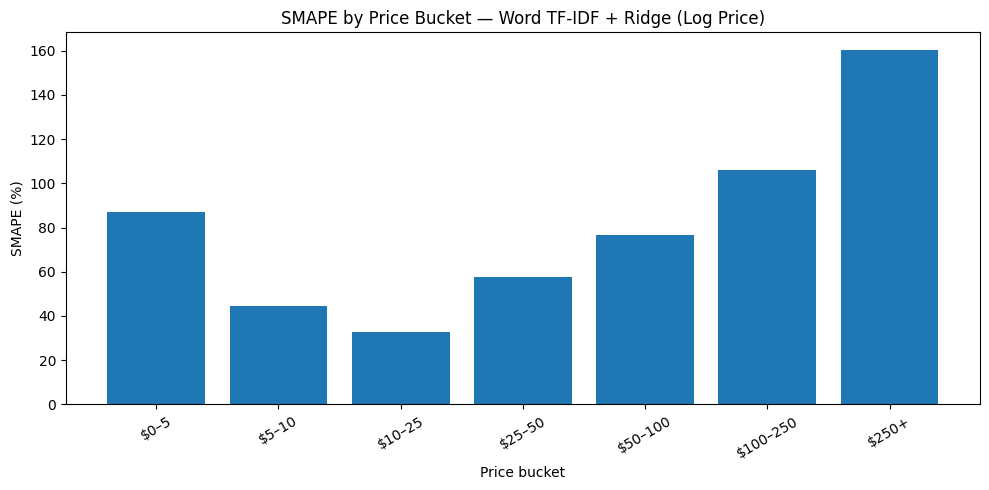

In [19]:
best_model_name = leaderboard.loc[0, 'model']

name_to_key = {
    'Median Constant Baseline': 'median_baseline',
    'Word TF-IDF + Ridge (Raw Price)': 'word_raw',
    'Word TF-IDF + Ridge (Log Price)': 'word_log',
    'Character TF-IDF + Ridge (Log Price)': 'char_log',
    'Word + Character TF-IDF Ensemble': 'word_char_ensemble',
}

best_key = name_to_key[best_model_name]
best_bucket = bucket_report[bucket_report['model'] == best_key].copy()

plt.figure(figsize=(10, 5))
plt.bar(best_bucket['price_bucket'], best_bucket['smape'])
plt.title(f'SMAPE by Price Bucket — {best_model_name}')
plt.xlabel('Price bucket')
plt.ylabel('SMAPE (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'v03_best_model_smape_by_bucket.png', dpi=150, bbox_inches='tight')
plt.show()

## 20. Save Validation Predictions

In [20]:
validation_predictions = valid_df[['sample_id', 'price']].copy()
validation_predictions = validation_predictions.rename(columns={'price': 'actual_price'})

validation_predictions['median_baseline'] = prediction_store['median_baseline']
validation_predictions['word_raw'] = prediction_store['word_raw']
validation_predictions['word_log'] = prediction_store['word_log']
validation_predictions['char_log'] = prediction_store['char_log']
validation_predictions['word_char_ensemble'] = prediction_store['word_char_ensemble']

validation_predictions.to_csv(
    PREDICTIONS_DIR / 'v03_validation_predictions.csv',
    index=False,
)

display(validation_predictions.head())

,sample_id,actual_price,median_baseline,word_raw,word_log,char_log,word_char_ensemble
0,55858,30.34,14.0,12.727586,10.066833,10.466188,10.066833
1,292686,66.49,14.0,60.485405,35.531723,35.042591,35.531723
2,9259,18.50,14.0,6.580546,8.624579,8.696526,8.624579
3,254947,15.99,14.0,21.995926,14.171900,10.782250,14.171900
4,271423,109.97,14.0,37.631634,28.844324,30.767126,28.844324


## 21. Inspect Largest Ensemble Errors

This gives us a first view of where text-only modeling fails.

In [21]:
error_analysis = valid_df[['sample_id', 'catalog_content', 'price']].copy()
error_analysis['prediction'] = ensemble_pred
error_analysis['absolute_error'] = np.abs(error_analysis['price'] - error_analysis['prediction'])

denom = (np.abs(error_analysis['price']) + np.abs(error_analysis['prediction'])) / 2
error_analysis['row_smape'] = np.where(
    denom == 0,
    0,
    np.abs(error_analysis['price'] - error_analysis['prediction']) / denom * 100,
)

print('Largest SMAPE errors')
display(
    error_analysis.nlargest(25, 'row_smape')[
        ['sample_id', 'price', 'prediction', 'row_smape', 'catalog_content']
    ]
)

Largest SMAPE errors


,sample_id,price,prediction,row_smape,catalog_content
6654,189266,0.680,39.709633,193.265599,"Item Name: Goya Papaya Nectar, 9.6 Ounce -- 24 per case.\nValue: 24.0\nUnit: Count\n"
386,88438,1.595,58.260815,189.341052,"Item Name: El Monterey All Natural Chicken, Monterey Jack Cheese and Rice Chimichanga, 0.312 Pound - 24 per case.\nBullet Point: Ships frozen, CANNOT be cancelled after being p..."
14604,190026,739.990,22.153448,188.373082,"Item Name: Crystal Geyser Pallet Of 84 Cases, Of Alpine 100% Natural Spring Water, 24 16.9oz bottles per Case, Bottled at The Source\nBullet Point 1: SIZE: Pallet of 84 Cases o..."
6746,218412,600.590,20.595366,186.738023,"Item Name: Mega Bulk Candy-Filled Plastic Easter Eggs - 2.5"" (2000 Pcs.) | Pre-Filled with Tootsie Rolls, Smarties, & Frooties - Perfect for Church, School, & Community Easter ..."
9381,188072,496.280,17.538809,186.346308,Item Name: Jenny Silks White Real Touch Phalaenopsis Silk Orchid Arrangement in a Natural Teak Bowl\nValue: 1.0\nUnit: Count\n
13105,187170,190.080,8.443373,182.987650,"Item Name: Pure Life, Purified Water, Plastic Bottled Water, Pallet of 78 Cases, Clear, 16.9 Fl Oz (Pack of 78)\nBullet Point 1: Everyday Hydration: Our 16.9 Fl Oz / 500mL Pure..."
14312,123813,255.950,11.592198,182.668606,Item Name: Twisted X Men's Ruff Stock Western Boot Square Toe Dark Brown 11.5 D(M) US\nBullet Point 1: Full-Grain Leather\nBullet Point 2: Pull Tabs\nBullet Point 3: Cushion Co...
2536,267237,2.290,49.136730,182.188251,"Item Name: P3 Turkey Breast Mild Cheddar Chocolate Peanut Nut Cluster, 2 Ounce -- 10 per case.\nValue: 10.0\nUnit: Count\n"
13698,164679,300.000,14.320379,181.776073,"Item Name: More Than Gourmet Glace D'agneau Gold, Roasted Lamb Stock, 1.5 Ounce (Pack of 1)\nBullet Point 1: RICH LAMB STOCK: Elevate the flavor of any dish by adding this tast..."
4462,173253,0.500,10.177686,181.269349,"Item Name: Pelon Pelo Rico Tamarind Soft Candy, 1-Ounce package (Pack of 12)\nBullet Point 1: Perfect for snacking and gift-giving\nBullet Point 2: Tangy tamarind chili flavor\..."


## 22. Save Trained Baseline Models

In [22]:
joblib.dump(word_vectorizer, MODELS_DIR / 'word_tfidf_vectorizer.joblib')
joblib.dump(word_ridge_raw, MODELS_DIR / 'word_ridge_raw.joblib')
joblib.dump(word_ridge_log, MODELS_DIR / 'word_ridge_log.joblib')
joblib.dump(char_vectorizer, MODELS_DIR / 'char_tfidf_vectorizer.joblib')
joblib.dump(char_ridge_log, MODELS_DIR / 'char_ridge_log.joblib')

ensemble_config = {
    'word_weight': best_word_weight,
    'char_weight': best_char_weight,
    'word_model_target': 'log1p(price)',
    'char_model_target': 'log1p(price)',
    'minimum_prediction': 0.01,
}

with (MODELS_DIR / 'ensemble_config.json').open('w') as f:
    json.dump(ensemble_config, f, indent=2)

print('Saved V0.3 model artifacts to:', MODELS_DIR)

Saved V0.3 model artifacts to: /Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/models/v03_text_baselines


## 23. Save Experiment Metadata

In [23]:
metadata = {
    'version': 'V0.3',
    'random_state': RANDOM_STATE,
    'training_rows': int(len(train_df)),
    'validation_rows': int(len(valid_df)),
    'group_overlap': int(len(overlap_groups)),
    'word_vocabulary_size': int(len(word_vectorizer.vocabulary_)),
    'char_vocabulary_size': int(len(char_vectorizer.vocabulary_)),
    'best_model': str(leaderboard.loc[0, 'model']),
    'best_smape': float(leaderboard.loc[0, 'smape']),
    'ensemble_word_weight': best_word_weight,
    'ensemble_char_weight': best_char_weight,
}

with (METRICS_DIR / 'v03_experiment_metadata.json').open('w') as f:
    json.dump(metadata, f, indent=2)

display(pd.Series(metadata, name='value').to_frame())

,value
version,V0.3
random_state,42
training_rows,60000
validation_rows,15000
group_overlap,0
word_vocabulary_size,180000
char_vocabulary_size,202472
best_model,Word TF-IDF + Ridge (Log Price)
best_smape,54.460909
ensemble_word_weight,1.0


## 24. V0.3 Final Summary

In [24]:
print('=' * 78)
print('PRICEFUSION V0.3 — TEXT BASELINES COMPLETE')
print('=' * 78)
print(f'Training rows       : {len(train_df):,}')
print(f'Validation rows     : {len(valid_df):,}')
print(f'Group overlap       : {len(overlap_groups)}')
print(f'Word vocabulary     : {len(word_vectorizer.vocabulary_):,}')
print(f'Character vocabulary: {len(char_vectorizer.vocabulary_):,}')
print('-' * 78)
print('Leaderboard:')
for _, row in leaderboard.iterrows():
    print(f"{row['model']:<45} SMAPE={row['smape']:.4f}%   MAE={row['mae']:.4f}")
print('-' * 78)
print(f"BEST MODEL : {leaderboard.loc[0, 'model']}")
print(f"BEST SMAPE : {leaderboard.loc[0, 'smape']:.4f}%")
print('=' * 78)
print('Next milestone: PriceFusion V0.4 — Advanced Structured Feature Engineering')

PRICEFUSION V0.3 — TEXT BASELINES COMPLETE
Training rows       : 60,000
Validation rows     : 15,000
Group overlap       : 0
Word vocabulary     : 180,000
Character vocabulary: 202,472
------------------------------------------------------------------------------
Leaderboard:
Word TF-IDF + Ridge (Log Price)               SMAPE=54.4609%   MAE=12.3154
Word + Character TF-IDF Ensemble              SMAPE=54.4609%   MAE=12.3154
Character TF-IDF + Ridge (Log Price)          SMAPE=56.3653%   MAE=12.7916
Word TF-IDF + Ridge (Raw Price)               SMAPE=62.5863%   MAE=13.4996
Median Constant Baseline                      SMAPE=71.9863%   MAE=16.2358
------------------------------------------------------------------------------
BEST MODEL : Word TF-IDF + Ridge (Log Price)
BEST SMAPE : 54.4609%
Next milestone: PriceFusion V0.4 — Advanced Structured Feature Engineering
